# Dynamic agent staffing: walkthrough

This notebook runs the `staffing` package end to end on **synthetic data** (the case-study data is confidential). The numbers show how the pieces fit together; they are not the real results. Those are in the README.

**The problem.** Eligible new advertisers get 60 days of onboarding support from an agent. Each agent supports up to 10 advertisers at a time. A new hire is unavailable for their first 30 days, and firing costs 30 days of salary plus 40% of annual salary. Each supported advertiser earns 13.5% of their projected annual budget. Every day we decide how many agents to hire or fire.

In [1]:
import pandas as pd

from staffing import (
    CORRECTED,
    LookaheadPolicy,
    load_config,
    load_synthetic,
    make_forecaster,
    plots,
    reproduce_original,
    run_experiment,
    simulate,
)

cfg = load_config()
data = load_synthetic(seed=cfg.seed)
usa = data.country_info("USA")
usa

CountryInfo(country='USA', salary=77721.0, threshold=35000.0, existing_agents=652)

## Demand

Only sign-ups with a projected budget above the country threshold are eligible. The original notebooks counted every sign-up as demand, which overstates it about 2.4x.

mean daily sign-ups: 104, eligible: 43


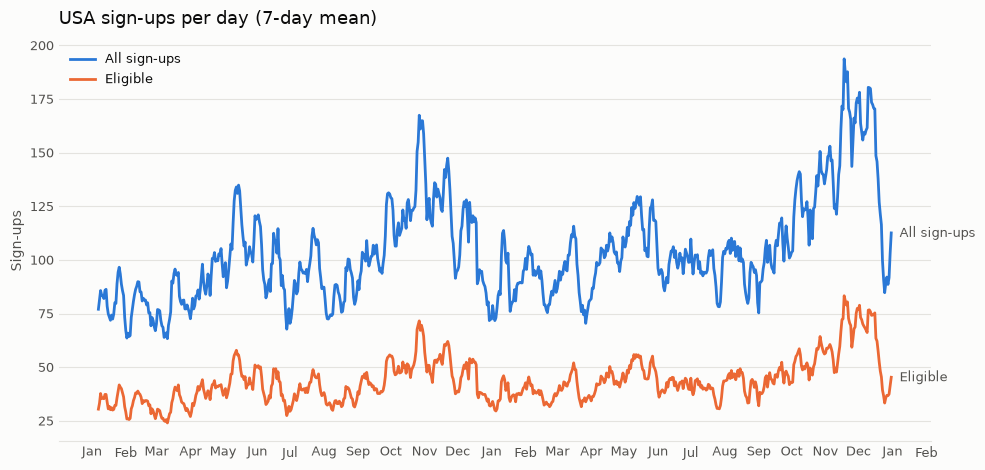

In [2]:
everyone = data.daily_demand("USA", eligible_only=False)
eligible = data.daily_demand("USA")
print(f"mean daily sign-ups: {everyone.mean():.0f}, eligible: {eligible.mean():.0f}")
weekly = {"All sign-ups": everyone.rolling(7).mean(), "Eligible": eligible.rolling(7).mean()}
plots.plot_lines(weekly, "USA sign-ups per day (7-day mean)", "Sign-ups");

## One simulated year

The lookahead policy compares forecast demand over the next 30 days (D) with the slots that free up within 30 days (S). It hires when D > beta·S and fires when S > alpha·D. Here the "forecast" is the actual 2023 demand (perfect foresight).

In [3]:
dates = pd.date_range("2023-01-01", "2023-12-31")
arrivals = data.arrivals("USA", dates)  # each eligible advertiser with their own budget
result = simulate(arrivals, dates, LookaheadPolicy(alpha=2.5, beta=1.0), eligible,
                  usa.existing_agents, usa.salary, cfg.params)
m = {k: getattr(result, k) / 1e6 for k in ("profit", "revenue", "cost")}
print(f"profit ${m['profit']:.1f}M = revenue ${m['revenue']:.1f}M - cost ${m['cost']:.1f}M")
result.daily[["signups", "hires", "fires", "agents", "idle_agents", "waiting", "profit"]].head()

profit $139.6M = revenue $176.2M - cost $36.6M


,signups,hires,fires,agents,idle_agents,waiting,profit
date,,,,,,,
2023-01-01,22,0,391,261,258,0,-1.442536e+07
2023-01-02,28,0,0,261,256,0,2.766849e+05
2023-01-03,51,0,0,261,250,0,5.649171e+05
2023-01-04,35,0,0,261,247,0,4.379427e+05
2023-01-05,23,0,0,261,245,0,2.008835e+05


Note the large firing on day one. The case's 652 existing USA agents are far more than about 42 eligible sign-ups a day need, roughly 250 agents at full utilisation.

## Forecasting

Each forecaster is fit on 2023 only and predicts 2024. Predicting a date inside the training history raises an error, so test data cannot leak in.

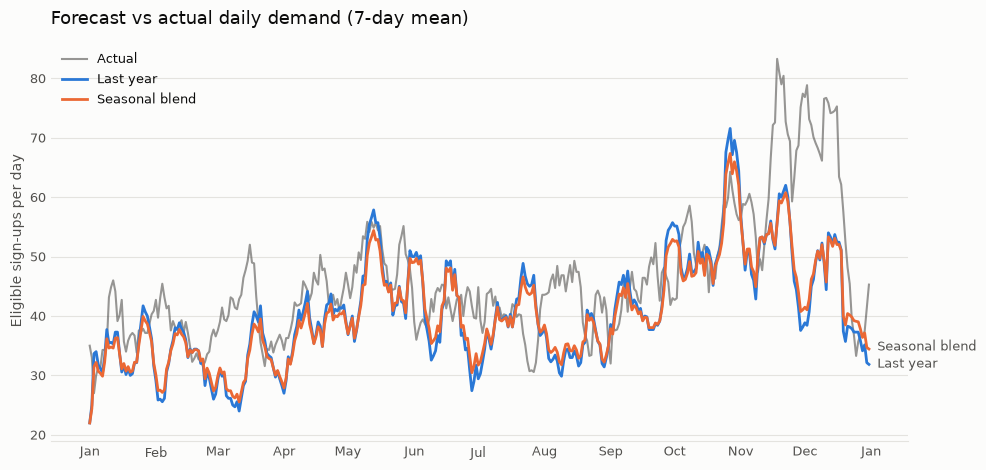

In [4]:
history = eligible[:"2023-12-31"]
test = pd.date_range("2024-01-01", "2024-12-31")
forecasts = {name: make_forecaster(name, **cfg.forecasters[name]).fit(history).predict(test)
             for name in ["seasonal_naive", "seasonal_blend"]}
plots.plot_forecasts(eligible[test], forecasts);

## Train on 2023, test on 2024

Policy parameters are tuned by grid search on 2023 with perfect foresight, then tested on 2024 with each forecaster. (SARIMA is left out here because order selection takes about 30 seconds; `scripts/run_experiment.py` includes it.)

In [5]:
exp = run_experiment(data, cfg, CORRECTED, forecasters=["seasonal_naive", "seasonal_blend"])
table = exp.results[["policy", "period", "forecaster", "params", "profit"]].copy()
table["profit"] = (table["profit"] / 1e6).round(1).astype(str) + "M"
table

,policy,period,forecaster,params,profit
0,baseline,train 2023,perfect_foresight,"hire=0, fire=2",128.6M
1,baseline,test 2024,perfect_foresight,"hire=0, fire=2",154.0M
2,baseline,test 2024,seasonal_naive,"hire=0, fire=2",150.3M
3,baseline,test 2024,seasonal_blend,"hire=0, fire=2",151.0M
4,lookahead,train 2023,perfect_foresight,"beta=1.25, alpha=2.5",139.8M
5,lookahead,test 2024,perfect_foresight,"beta=1.25, alpha=2.5",163.5M
6,lookahead,test 2024,seasonal_naive,"beta=1.25, alpha=2.5",160.7M
7,lookahead,test 2024,seasonal_blend,"beta=1.25, alpha=2.5",159.8M


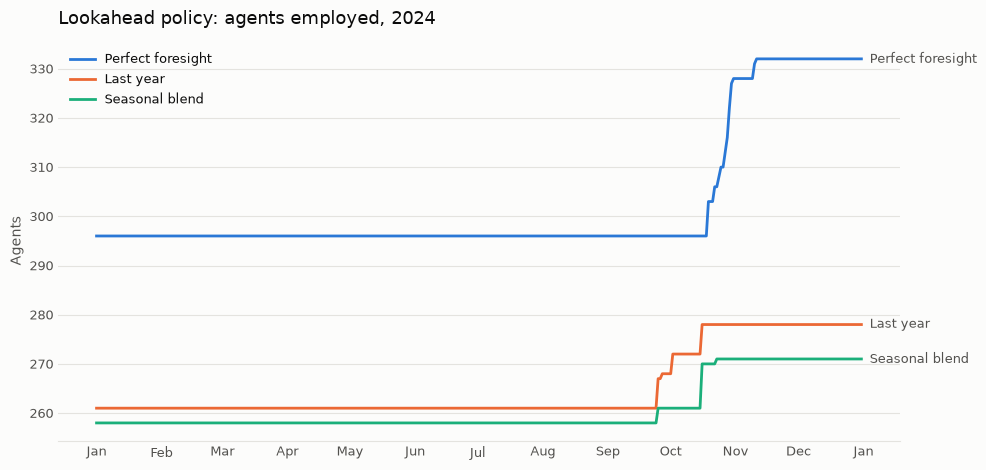

In [6]:
daily = {fc: df for (p, fc), df in exp.daily.items() if p == "lookahead"}
plots.plot_daily(daily, "agents", "Lookahead policy: agents employed, 2024", "Agents");

## Reproducing the original notebooks

`reproduce_original` re-runs the original analysis in the legacy model: all sign-ups counted as demand, a shared daily budget, the firing-loop bug, and the leaky blend forecast. The test suite checks this simulator against the team's original `run_strategy` and requires an exact match. On the real data the `reproduced` column should match `original_real_data`; on synthetic data only the method is shared.

In [7]:
repro = reproduce_original(data, cfg)
repro.assign(**{c: (repro[c] / 1e6).round(1) for c in ["original_real_data", "reproduced"]})

,setting,params,original_real_data,reproduced
0,"Baseline, tuned on 2023 (perfect foresight)","hire=2, fire=1",206.0,364.4
1,"Lookahead, tuned on 2023 (perfect foresight)","beta=1, alpha=2.93878",301.4,369.9
2,"Baseline, 2024, last year as forecast","hire=2, fire=1",206.5,410.4
3,"Lookahead, 2024, last year as forecast","alpha=2.16, beta=1",282.4,382.5
4,"Baseline, 2024, leaky blend forecast","hire=3, fire=1",292.7,416.8
5,"Lookahead, 2024, leaky blend, alpha tuned on 2024","beta=1, alpha=21.8263",294.5,420.7
